In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df= pd.read_csv(r"C:\Users\DELL\Desktop\PROJECT-1\amazon.csv")

In [3]:
import pandas as pd
import numpy as np


In [4]:
column_info = pd.DataFrame({
    "Column Name": df.columns,
    "Data Type": df.dtypes.values
})

column_info


,Column Name,Data Type
0,product_id,str
1,product_name,str
2,category,str
3,discounted_price,str
4,actual_price,str
5,discount_percentage,str
6,rating,str
7,rating_count,str
8,about_product,str
9,user_id,str


In [5]:
# Missing Values
missing_values = pd.DataFrame({
    "Column Name": df.columns,
    "Missing Values": df.isnull().sum().values
})

missing_values

,Column Name,Missing Values
0,product_id,0
1,product_name,0
2,category,0
3,discounted_price,0
4,actual_price,0
5,discount_percentage,0
6,rating,0
7,rating_count,2
8,about_product,0
9,user_id,0


In [6]:
# Duplicate Values
print("Number of Duplicate Rows:", df.duplicated().sum())

Number of Duplicate Rows: 0


In [7]:
#Remove duplicate rows

df = df.drop_duplicates()

# Clean Price columns
df["discounted_price"] = (
    df["discounted_price"]
    .astype(str)
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .astype(float)
)

df["actual_price"] = (
    df["actual_price"]
    .astype(str)
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .astype(float)
)

# Clean Discount Percentage
df["discount_percentage"] = (
    df["discount_percentage"]
    .astype(str)
    .str.replace("%", "", regex=False)
    .astype(float)
)

# Clean Rating
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")

# Clean Rating Count
df["rating_count"] = (
    df["rating_count"]
    .astype(str)
    .str.replace(",", "", regex=False)
)

df["rating_count"] = pd.to_numeric(df["rating_count"], errors="coerce")

print("Data Cleaning Completed Successfully!")


Data Cleaning Completed Successfully!


In [8]:
cleaned_info = pd.DataFrame({
    "Column Name": df.columns,
    "Data Type": df.dtypes.values
})

cleaned_info
df.head()

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,64.0,4.2,24269.0,High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,199.0,349.0,43.0,4.0,43994.0,"Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,199.0,1899.0,90.0,3.9,7928.0,【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,329.0,699.0,53.0,4.2,94363.0,The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,154.0,399.0,61.0,4.2,16905.0,[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


In [9]:
category_count = df["category"].value_counts()

category_count

category
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables                                          233
Electronics|WearableTechnology|SmartWatches                                                                                 76
Electronics|Mobiles&Accessories|Smartphones&BasicMobiles|Smartphones                                                        68
Electronics|HomeTheater,TV&Video|Televisions|SmartTelevisions                                                               63
Electronics|Headphones,Earbuds&Accessories|Headphones|In-Ear                                                                52
                                                                                                                          ... 
Home&Kitchen|Kitchen&HomeAppliances|SmallKitchenAppliances|RotiMakers                                                        1
Home&Kitchen|Heating,Cooling&AirQuality|Parts&Accessories|FanParts&Accessories                        

C:\Users\DELL\AppData\Local\Temp\ipykernel_3208\3777783801.py:9: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


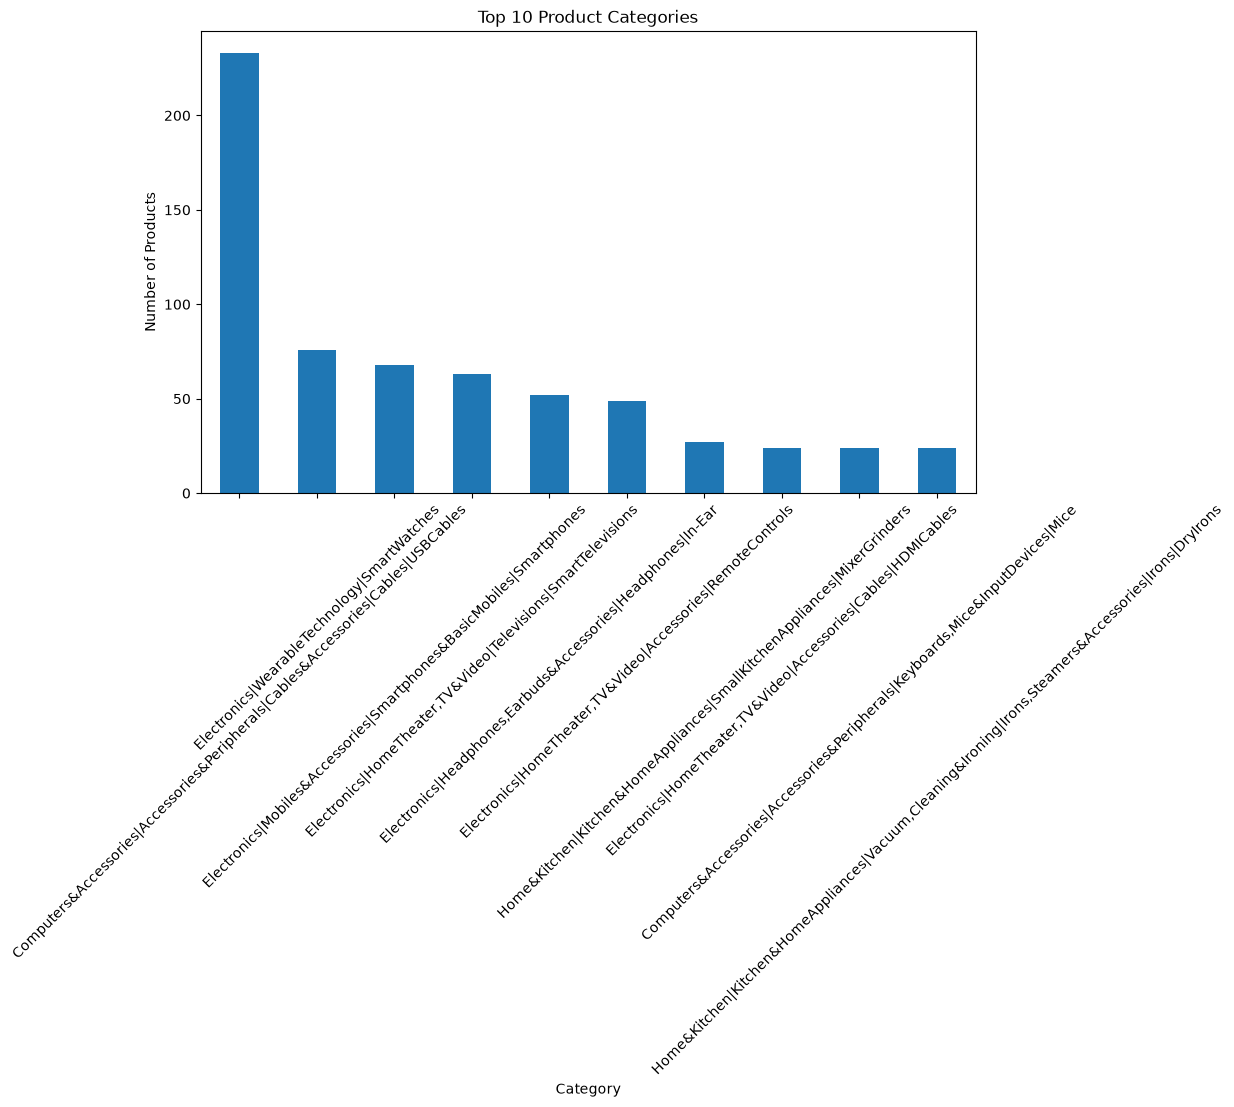

In [10]:
plt.figure(figsize=(10, 6))

category_count.head(10).plot(kind="bar")

plt.title("Top 10 Product Categories")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
category_count = df["category"].value_counts().head(10)

category_count

category
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables                        233
Electronics|WearableTechnology|SmartWatches                                                               76
Electronics|Mobiles&Accessories|Smartphones&BasicMobiles|Smartphones                                      68
Electronics|HomeTheater,TV&Video|Televisions|SmartTelevisions                                             63
Electronics|Headphones,Earbuds&Accessories|Headphones|In-Ear                                              52
Electronics|HomeTheater,TV&Video|Accessories|RemoteControls                                               49
Home&Kitchen|Kitchen&HomeAppliances|SmallKitchenAppliances|MixerGrinders                                  27
Electronics|HomeTheater,TV&Video|Accessories|Cables|HDMICables                                            24
Computers&Accessories|Accessories&Peripherals|Keyboards,Mice&InputDevices|Mice                            24
Home&Kitch

C:\Users\DELL\AppData\Local\Temp\ipykernel_3208\3609979616.py:9: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


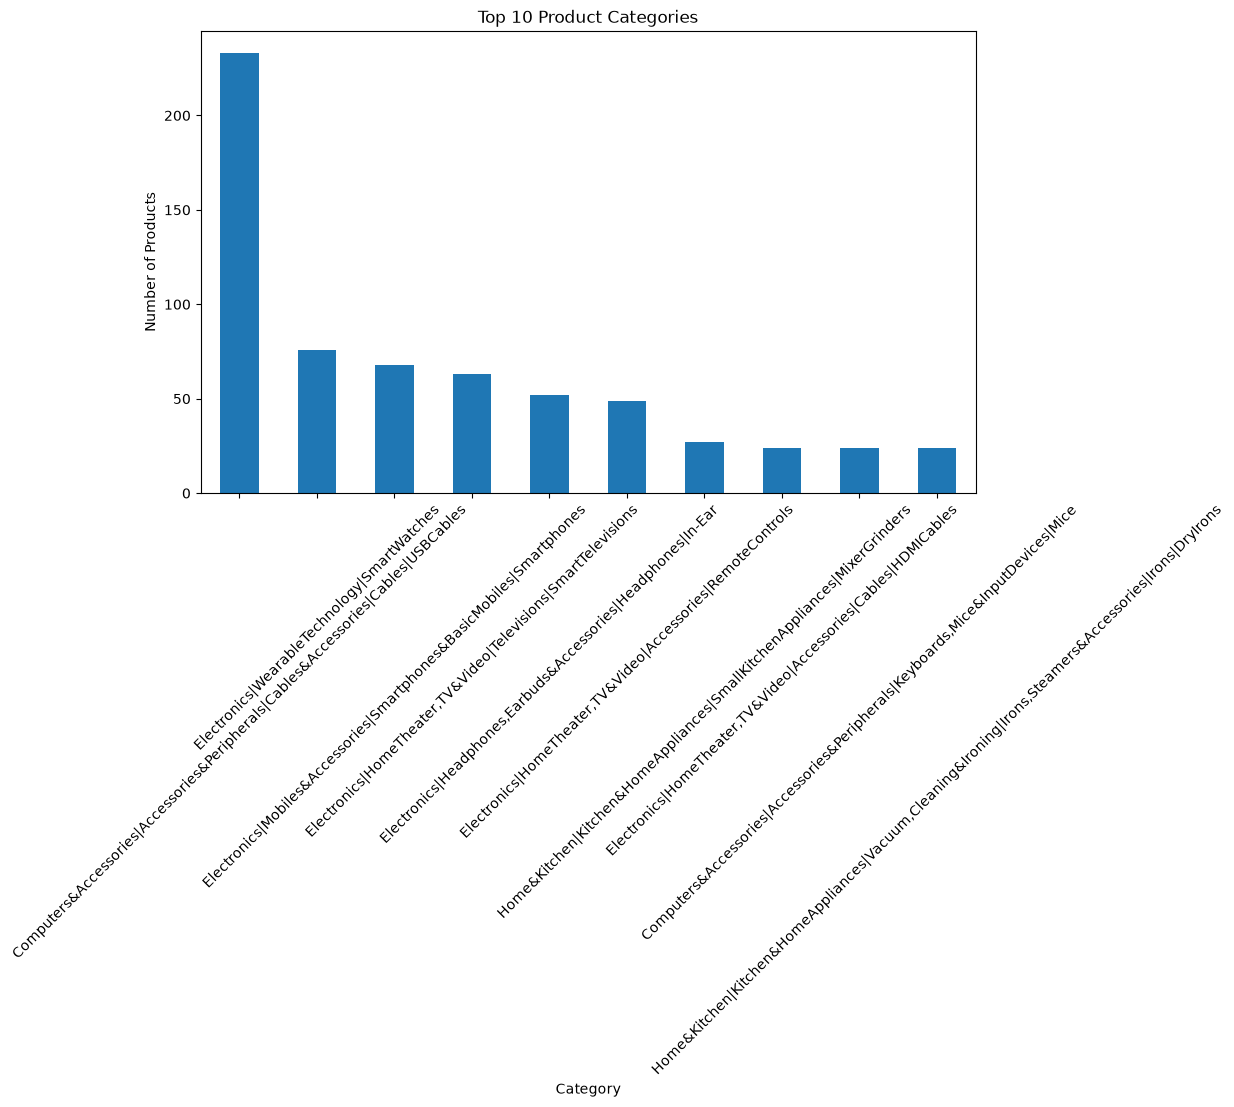

In [12]:
plt.figure(figsize=(10, 6))

category_count.plot(kind="bar")

plt.title("Top 10 Product Categories")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:

print("Minimum Actual Price:", df["actual_price"].min())
print("Maximum Actual Price:", df["actual_price"].max())

Minimum Actual Price: 39.0
Maximum Actual Price: 139900.0


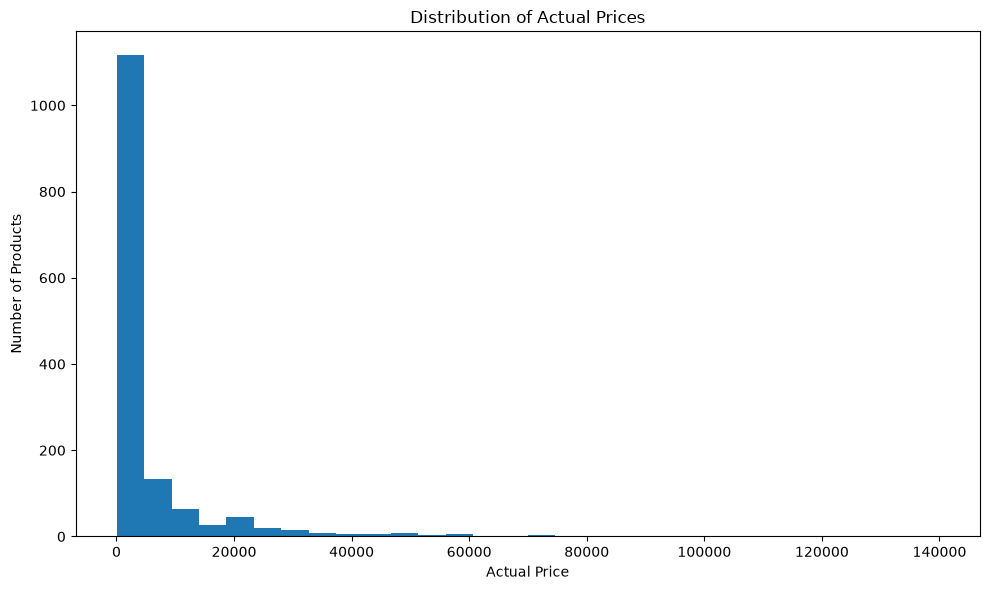

In [14]:
plt.figure(figsize=(10, 6))

plt.hist(df["actual_price"], bins=30)

plt.title("Distribution of Actual Prices")
plt.xlabel("Actual Price")
plt.ylabel("Number of Products")

plt.tight_layout()
plt.show()

In [15]:
print(df["discount_percentage"].head())
print(df["discount_percentage"].dtype)

0    64.0
1    43.0
2    90.0
3    53.0
4    61.0
Name: discount_percentage, dtype: float64
float64


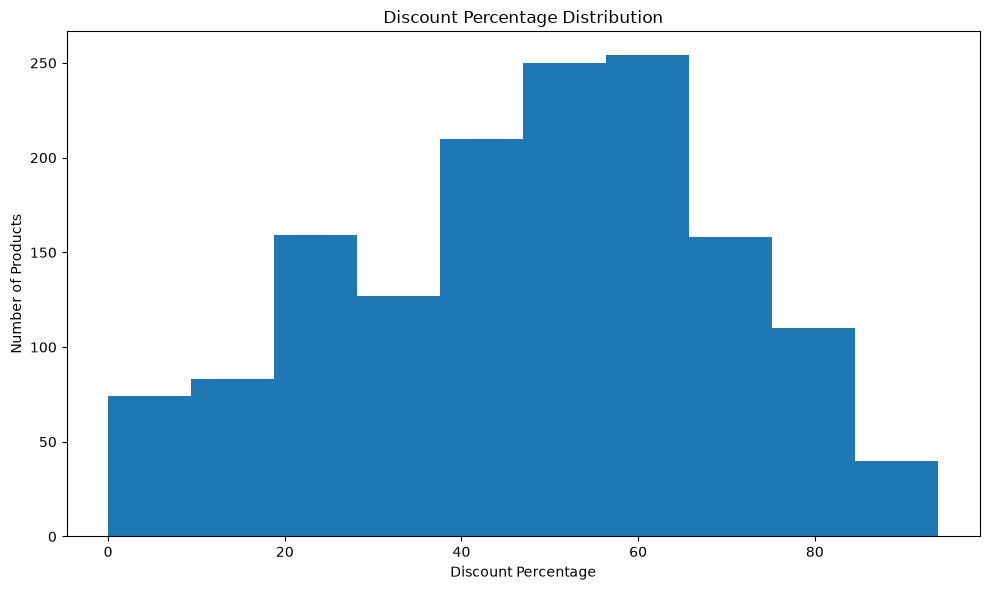

In [16]:
plt.figure(figsize=(10, 6))

plt.hist(df["discount_percentage"], bins=10)

plt.title("Discount Percentage Distribution")
plt.xlabel("Discount Percentage")
plt.ylabel("Number of Products")

plt.tight_layout()
plt.show()

In [17]:
rating_summary = pd.DataFrame({
    "Rating Analysis": [
        "Average Rating",
        "Minimum Rating",
        "Maximum Rating"
    ],
    "Value": [
        df["rating"].mean(),
        df["rating"].min(),
        df["rating"].max()
    ]
})

rating_summary

,Rating Analysis,Value
0,Average Rating,4.096585
1,Minimum Rating,2.000000
2,Maximum Rating,5.000000


In [18]:
top_products = df.nlargest(10, "rating_count")[
    ["product_name", "rating_count", "rating"]
]

top_products

,product_name,rating_count,rating
12,AmazonBasics Flexible Premium HDMI Cable (Blac...,426973.0,4.4
47,"Amazon Basics High-Speed HDMI Cable, 6 Feet - ...",426973.0,4.4
65,"Amazon Basics High-Speed HDMI Cable, 6 Feet (2...",426973.0,4.4
684,AmazonBasics Flexible Premium HDMI Cable (Blac...,426972.0,4.4
352,boAt Bassheads 100 in Ear Wired Earphones with...,363713.0,4.1
400,boAt Bassheads 100 in Ear Wired Earphones with...,363713.0,4.1
584,boAt BassHeads 100 in-Ear Wired Headphones wit...,363711.0,4.1
370,"Redmi 9 Activ (Carbon Black, 4GB RAM, 64GB Sto...",313836.0,4.1
371,"Redmi 9A Sport (Coral Green, 2GB RAM, 32GB Sto...",313836.0,4.1
473,"Redmi 9A Sport (Carbon Black, 2GB RAM, 32GB St...",313832.0,4.1


In [19]:
category_rating = df.groupby("category")["rating"].mean().sort_values(ascending=False)

category_rating

category
Computers&Accessories|Tablets                                                                                    4.6
Computers&Accessories|NetworkingDevices|NetworkAdapters|PowerLANAdapters                                         4.5
Electronics|Cameras&Photography|Accessories|Film                                                                 4.5
Computers&Accessories|Components|Memory                                                                          4.5
Electronics|HomeAudio|MediaStreamingDevices|StreamingClients                                                     4.5
                                                                                                                ... 
Computers&Accessories|Accessories&Peripherals|Audio&VideoAccessories|PCMicrophones                               3.6
Electronics|HomeTheater,TV&Video|Accessories|3DGlasses                                                           3.5
Computers&Accessories|Accessories&Peripherals|Audio&Vid

In [20]:
category_rating = df.groupby("category")["rating"].mean().sort_values(ascending=False)

category_rating

category
Computers&Accessories|Tablets                                                                                    4.6
Computers&Accessories|NetworkingDevices|NetworkAdapters|PowerLANAdapters                                         4.5
Electronics|Cameras&Photography|Accessories|Film                                                                 4.5
Computers&Accessories|Components|Memory                                                                          4.5
Electronics|HomeAudio|MediaStreamingDevices|StreamingClients                                                     4.5
                                                                                                                ... 
Computers&Accessories|Accessories&Peripherals|Audio&VideoAccessories|PCMicrophones                               3.6
Electronics|HomeTheater,TV&Video|Accessories|3DGlasses                                                           3.5
Computers&Accessories|Accessories&Peripherals|Audio&Vid

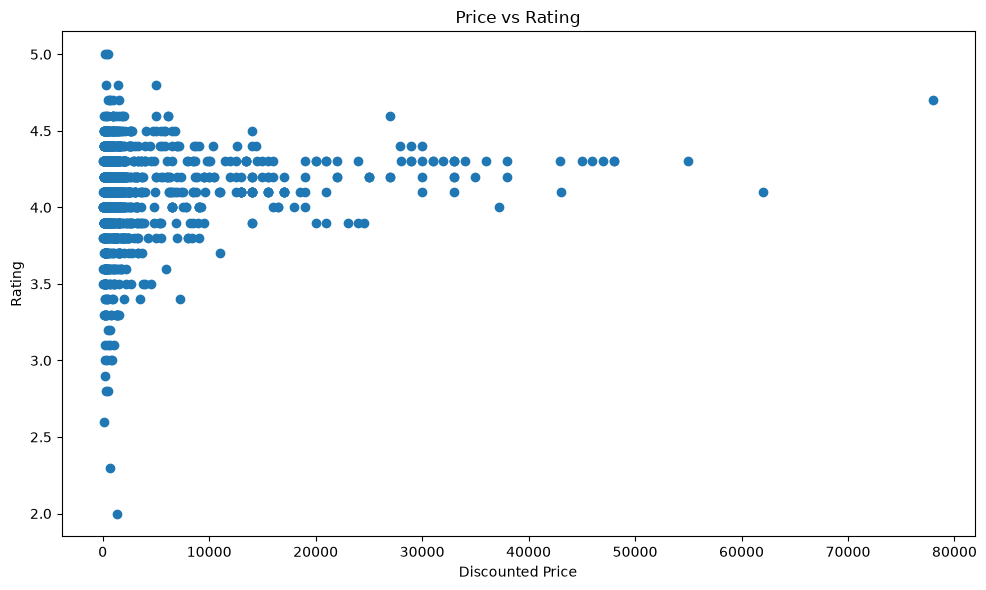

In [21]:
plt.figure(figsize=(10, 6))

plt.scatter(df["discounted_price"], df["rating"])

plt.title("Price vs Rating")
plt.xlabel("Discounted Price")
plt.ylabel("Rating")

plt.tight_layout()
plt.show()

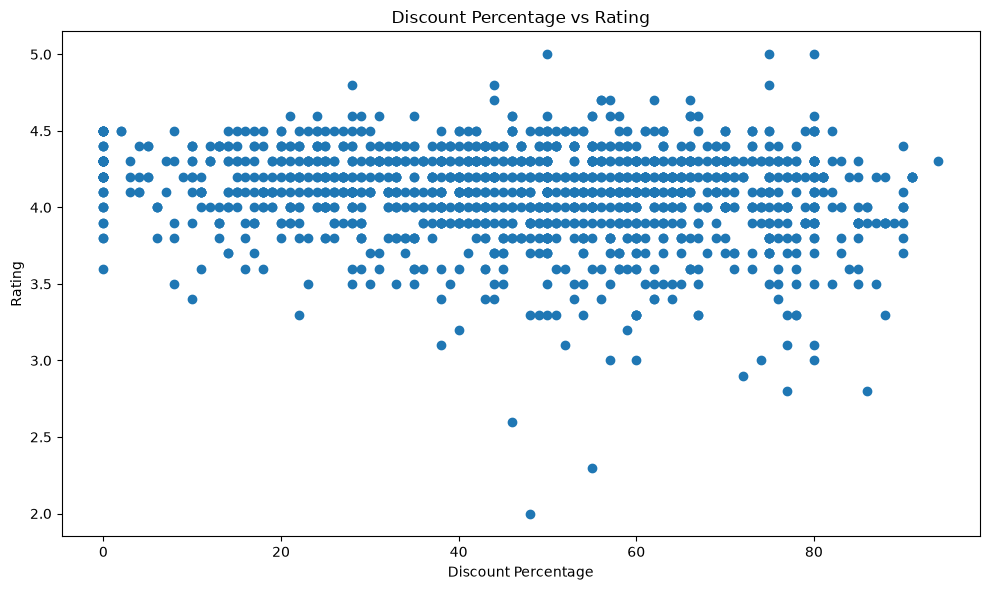

In [22]:
plt.figure(figsize=(10, 6))

plt.scatter(df["discount_percentage"], df["rating"])

plt.title("Discount Percentage vs Rating")
plt.xlabel("Discount Percentage")
plt.ylabel("Rating")

plt.tight_layout()
plt.show()

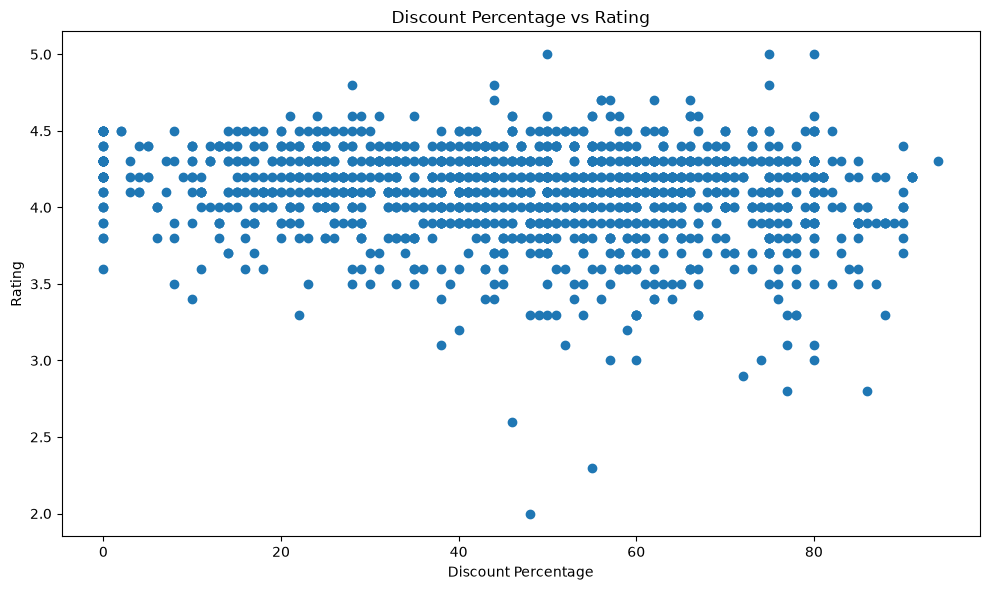

In [23]:
plt.figure(figsize=(10, 6))

plt.scatter(df["discount_percentage"], df["rating"])

plt.title("Discount Percentage vs Rating")
plt.xlabel("Discount Percentage")
plt.ylabel("Rating")

plt.tight_layout()
plt.show()

In [24]:
review_summary = pd.DataFrame({
    "Review Analysis": [
        "Total Reviews",
        "Positive Reviews",
        "Negative Reviews"
    ],
    "Value": [
        df["review_content"].notnull().sum(),
        df["review_content"].str.contains(
            "good|excellent|great|best|nice",
            case=False,
            na=False
        ).sum(),
        df["review_content"].str.contains(
            "bad|poor|worst|waste|disappointed",
            case=False,
            na=False
        ).sum()
    ]
})

review_summary

,Review Analysis,Value
0,Total Reviews,1465
1,Positive Reviews,1450
2,Negative Reviews,407


In [25]:
def sentiment(text):
    text = str(text).lower()

    positive_words = [
        "good", "great", "excellent", "best",
        "nice", "amazing", "awesome", "perfect"
    ]

    negative_words = [
        "bad", "poor", "worst", "waste",
        "disappointed", "terrible", "issue"
    ]

    if any(word in text for word in positive_words):
        return "Positive"
    elif any(word in text for word in negative_words):
        return "Negative"
    else:
        return "Neutral"


df["sentiment"] = df["review_content"].apply(sentiment)

df["sentiment"].value_counts()

sentiment
Positive    1453
Neutral        7
Negative       5
Name: count, dtype: int64

In [26]:
correlation = df[
    ["actual_price", "discounted_price", "discount_percentage", "rating", "rating_count"]
].corr()

correlation



,actual_price,discounted_price,discount_percentage,rating,rating_count
actual_price,1.000000,0.961915,-0.118098,0.121642,-0.036137
discounted_price,0.961915,1.000000,-0.242412,0.120337,-0.027261
discount_percentage,-0.118098,-0.242412,1.000000,-0.155375,0.011691
rating,0.121642,0.120337,-0.155375,1.000000,0.102235
rating_count,-0.036137,-0.027261,0.011691,0.102235,1.000000


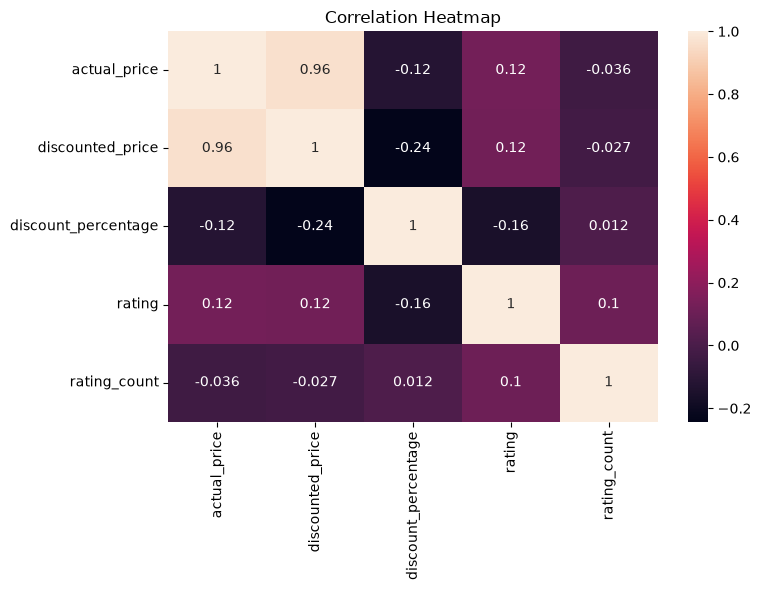

In [27]:
plt.figure(figsize=(8, 6))

sns.heatmap(correlation, annot=True)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [28]:
key_findings = pd.DataFrame({
    "Analysis": [
        "Total Products",
        "Average Actual Price",
        "Average Discounted Price",
        "Average Discount Percentage",
        "Average Rating"
    ],
    "Result": [
        len(df),
        df["actual_price"].mean(),
        df["discounted_price"].mean(),
        df["discount_percentage"].mean(),
        df["rating"].mean()
    ]
})

key_findings

,Analysis,Result
0,Total Products,1465.000000
1,Average Actual Price,5444.990635
2,Average Discounted Price,3125.310874
3,Average Discount Percentage,47.691468
4,Average Rating,4.096585


In [29]:
print("""
FINAL CONCLUSION

1. The Amazon dataset contains information about products, prices,
   discounts, ratings and customer reviews.

2. Data cleaning helped us prepare the dataset for accurate analysis.

3. Category-wise analysis helped identify the distribution of products
   across different categories.

4. Price and discount analysis helped us understand Amazon's pricing
   patterns.

5. Rating and rating-count analysis helped us understand customer
   satisfaction and product popularity.

6. Price vs Rating and Discount vs Rating analysis helped us study
   relationships between product attributes.

7. Customer review analysis provided additional insights into
   customer feedback.

Overall, this project shows how data analysis can convert raw Amazon
product data into useful business insights and support better
decision-making.
""")


FINAL CONCLUSION

1. The Amazon dataset contains information about products, prices,
   discounts, ratings and customer reviews.

2. Data cleaning helped us prepare the dataset for accurate analysis.

3. Category-wise analysis helped identify the distribution of products
   across different categories.

4. Price and discount analysis helped us understand Amazon's pricing
   patterns.

5. Rating and rating-count analysis helped us understand customer
   satisfaction and product popularity.

6. Price vs Rating and Discount vs Rating analysis helped us study
   relationships between product attributes.

7. Customer review analysis provided additional insights into
   customer feedback.

Overall, this project shows how data analysis can convert raw Amazon
product data into useful business insights and support better
decision-making.



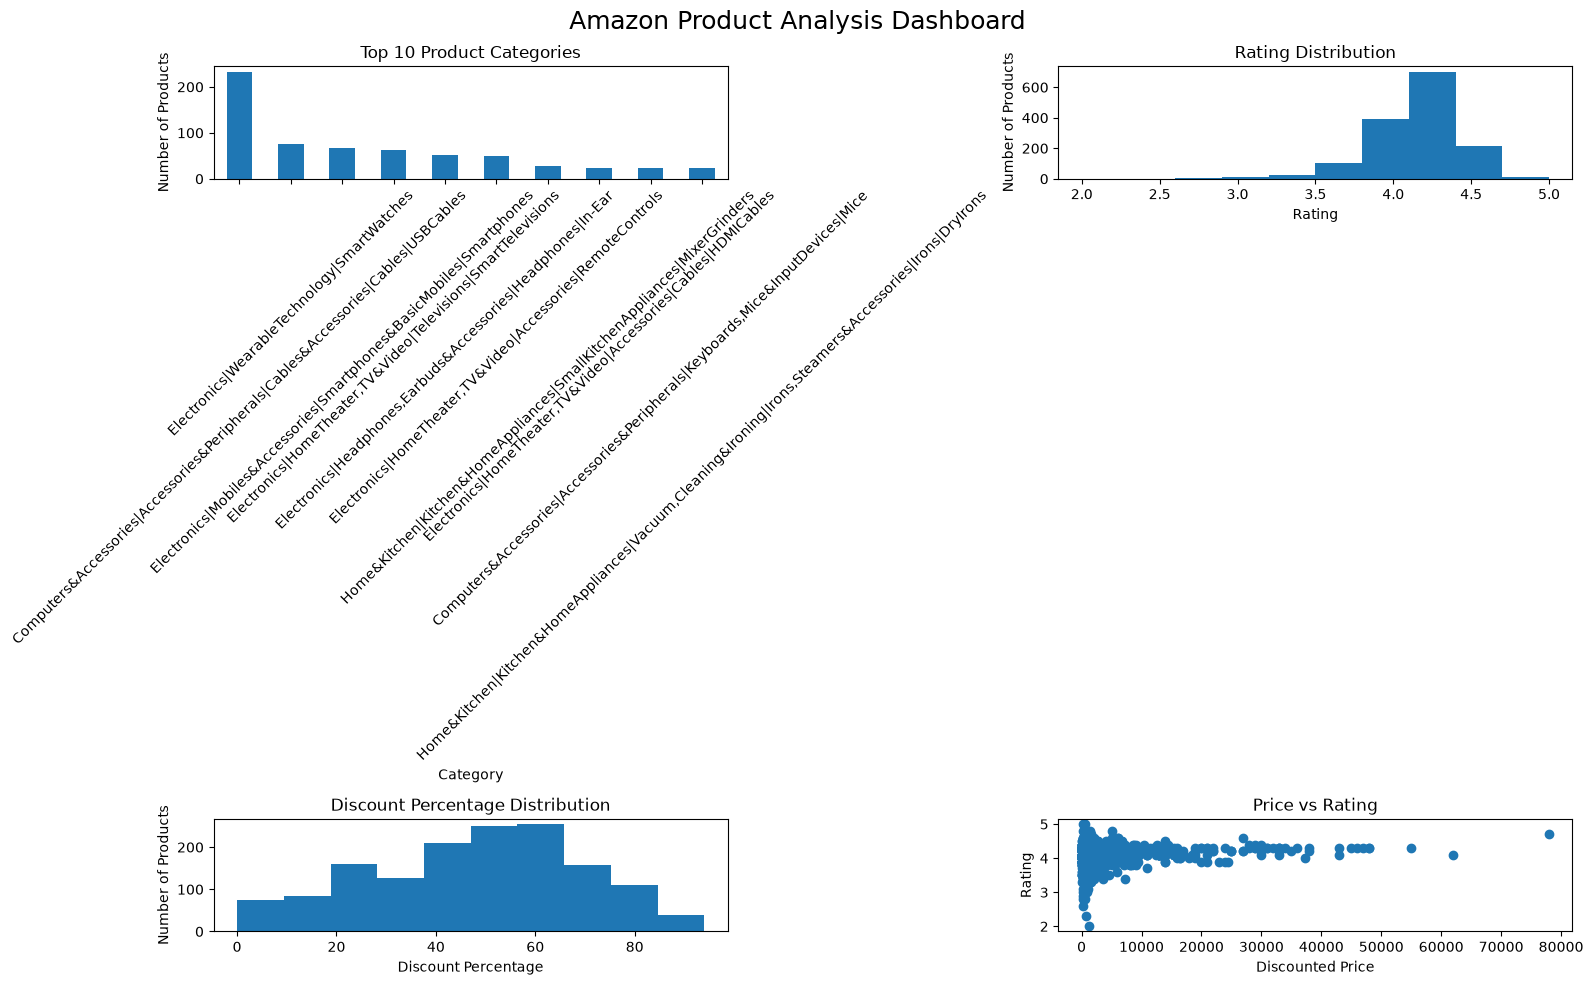

In [30]:
# Amazon Product Analysis Dashboard

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Top 10 Categories
df["category"].value_counts().head(10).plot(
    kind="bar", ax=axes[0, 0]
)
axes[0, 0].set_title("Top 10 Product Categories")
axes[0, 0].set_xlabel("Category")
axes[0, 0].set_ylabel("Number of Products")
axes[0, 0].tick_params(axis="x", rotation=45)

# 2. Rating Distribution
df["rating"].dropna().plot(
    kind="hist", bins=10, ax=axes[0, 1]
)
axes[0, 1].set_title("Rating Distribution")
axes[0, 1].set_xlabel("Rating")
axes[0, 1].set_ylabel("Number of Products")

# 3. Discount Distribution
df["discount_percentage"].dropna().plot(
    kind="hist", bins=10, ax=axes[1, 0]
)
axes[1, 0].set_title("Discount Percentage Distribution")
axes[1, 0].set_xlabel("Discount Percentage")
axes[1, 0].set_ylabel("Number of Products")

# 4. Price vs Rating
axes[1, 1].scatter(
    df["discounted_price"],
    df["rating"]
)
axes[1, 1].set_title("Price vs Rating")
axes[1, 1].set_xlabel("Discounted Price")
axes[1, 1].set_ylabel("Rating")

plt.suptitle(
    "Amazon Product Analysis Dashboard",
    fontsize=18
)

plt.tight_layout()
plt.show()